# Selección de la cartera de 3 acciones (Reto 9)

Queremos elegir la cartera para la call asiática con estructura *barbell*: 2 acciones no volátiles y 1 volátil, a partir de las 30 empresas del Dow Jones.

Pasos: 1. Datos · 2. Separación en volátiles y no volátiles · 3. Empresas volátiles y no volátiles · 4. Todos los tríos posibles

In [2]:
import yfinance as yf
import warnings
warnings.filterwarnings("ignore")

In [3]:
from matplotlib.colors import LinearSegmentedColormap

COLORES = {
    "azul_principal":  "#001391",
    "azul_claro":      "#4D5FC4",
    "azul_muy_claro":  "#B3BAE8",
    "gris_oscuro":     "#1A1A2E",
    "gris_medio":      "#6E7191",
    "gris_claro":      "#E4E4EC",
    "blanco":          "#FFFFFF",
    "acento":          "#FF4B4B",
}

MAPA_CORR = LinearSegmentedColormap.from_list("corr", [COLORES["acento"], COLORES["blanco"], COLORES["azul_principal"]])

## 1. Datos

Usamos los datos limpios del equipo de limpieza (`Datos/dowjones_limpio.csv`, rama `limpieza`), con una fila por fecha y empresa. Los pasamos a formato ancho (una columna por empresa) con el precio ajustado `adj_close`, que ya corrige splits y dividendos, igual que `auto_adjust=True` en yfinance.

In [4]:
import pandas as pd

limpio = pd.read_csv("Datos/dowjones_limpio.csv")
limpio["date"] = pd.to_datetime(limpio["date"], utc=True).dt.tz_localize(None)   

precios = limpio.pivot(index="date", columns="symbol", values="adj_close")
print(f"Datos de {precios.index.min():%Y-%m-%d} a {precios.index.max():%Y-%m-%d}")
precios

Datos de 2018-06-06 a 2025-12-31


symbol,AAPL,AMGN,AMZN,AXP,BA,CAT,CRM,CSCO,CVX,DIS,...,MSFT,NKE,NVDA,PG,SHW,TRV,UNH,V,VZ,WMT
date,,,,,,,,,,,,,,,,,,,,,
2018-06-06,45.665348,143.140976,84.787498,90.513535,357.617096,131.875412,133.010803,34.881676,86.575134,96.091446,...,94.516266,66.114029,6.548114,59.841732,122.481842,107.609100,215.247894,128.590714,30.700314,24.945873
2018-06-07,45.542931,142.945953,84.464996,90.970741,354.700775,131.690033,130.420258,34.400925,89.087212,96.619469,...,93.031563,66.122849,6.492547,60.976585,122.330109,109.097107,215.533524,126.288376,31.080812,25.060923
2018-06-08,45.128605,143.725830,84.199501,90.540451,355.634399,130.872650,131.028610,34.266945,88.722328,98.043282,...,93.723213,66.246666,6.477240,62.119499,123.249756,110.400215,217.005173,127.137627,31.188618,24.886873
2018-06-11,45.017952,143.967621,84.456001,90.719719,357.020325,131.698410,131.470184,34.432453,89.508217,98.392136,...,93.188339,65.972504,6.436242,62.401196,123.395248,109.710815,219.688751,126.354408,31.264711,24.869173
2018-06-12,45.265144,144.326355,84.937500,90.298386,356.712341,132.701096,133.707489,34.629478,89.171394,98.373283,...,93.428093,65.707169,6.484646,62.167782,124.609016,108.937401,219.515594,127.250832,30.953972,24.810169
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-24,273.066742,327.263580,232.380005,380.015900,218.160004,580.214355,263.453613,76.898811,146.411545,113.609474,...,484.943420,58.455666,188.169678,141.343964,323.045959,290.561615,321.228943,353.020172,38.390667,110.903755
2025-12-26,272.657806,326.254211,232.520004,377.972534,216.440002,579.458984,264.268005,77.036797,145.944580,112.696465,...,484.635406,59.361725,190.085190,141.588501,323.135315,288.860779,325.396545,352.880981,38.543015,111.032928
2025-12-29,273.016876,323.020386,232.070007,372.288849,217.250000,575.095581,264.416962,76.672119,146.888229,113.321678,...,484.029236,59.634518,187.780594,141.422195,322.926819,288.672943,322.562592,352.493286,38.543015,111.817924


## 2. Separación en volátiles y no volátiles

Primero calculamos y graficamos la volatilidad anualizada (σ · √252) de las 30 empresas, sin grupos. El corte lo decidimos a la vista del gráfico.

### 2.1 Volatilidad de cada empresa

In [5]:
import numpy as np, matplotlib.pyplot as plt

DIAS_ANIO = 252
rent = precios.pct_change(fill_method=None) 
vol = (rent.std() * np.sqrt(DIAS_ANIO)).sort_values()

### 2.2 Gráfico de volatilidades (todavía sin grupos)

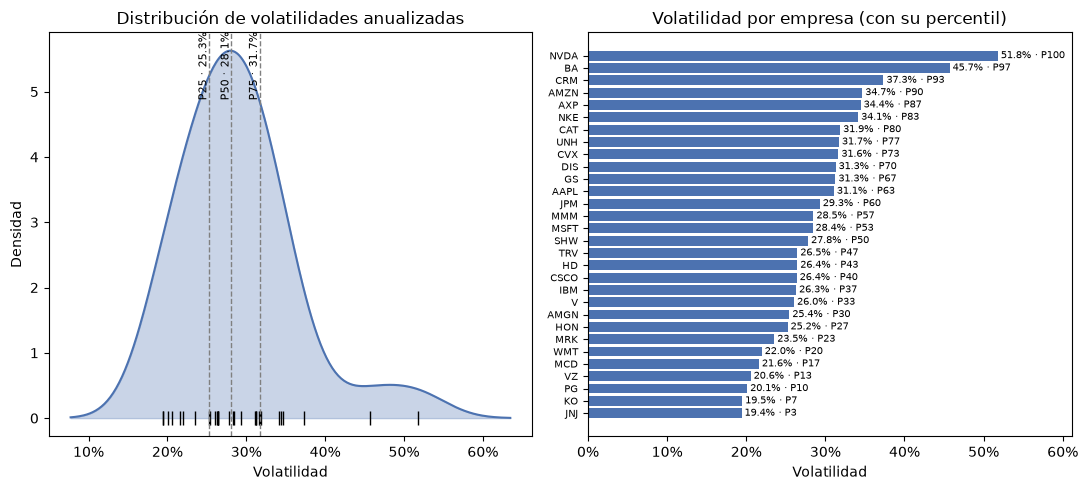

In [6]:
pct = vol.rank(pct=True).round(2)                            
fmt = lambda x, _: f"{x:.0%}"

def grafico(rojas=()):
    """Curva de distribución + barras por empresa. Las empresas de `rojas` salen en rojo."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5))

    h = 1.06 * vol.std() * len(vol) ** -0.2                
    x = np.linspace(vol.min() - 3 * h, vol.max() + 3 * h, 300)
    dens = np.exp(-0.5 * ((x[:, None] - vol.values) / h) ** 2).sum(axis=1) / (len(vol) * h * np.sqrt(2 * np.pi))
    ax1.plot(x, dens, color="#4c72b0")
    ax1.fill_between(x, dens, color="#4c72b0", alpha=0.3)
    ax1.plot(vol, np.zeros(len(vol)), "|", color="black", ms=10, clip_on=False) 
    for q in (0.25, 0.50, 0.75):
        v = vol.quantile(q)
        ax1.axvline(v, color="gray", ls="--", lw=1)
        ax1.text(v, ax1.get_ylim()[1], f"P{q*100:.0f} · {v:.1%}", rotation=90, va="top", ha="right", fontsize=8)
    ax1.set(title="Distribución de volatilidades anualizadas", xlabel="Volatilidad", ylabel="Densidad")

    ax2.barh(vol.index, vol, color=["#c44e52" if e in rojas else "#4c72b0" for e in vol.index])
    for i, (v, p) in enumerate(zip(vol, pct)):
        ax2.text(v, i, f" {v:.1%} · P{p*100:.0f}", va="center", fontsize=7)
    ax2.set(title="Volatilidad por empresa (con su percentil)", xlabel="Volatilidad")
    ax2.tick_params(axis="y", labelsize=7)
    ax2.margins(x=0.18)

    if len(rojas):                                           
        corte = vol[list(rojas)].min()
        ax1.fill_between(x, dens, where=x >= corte - 1e-9, color="#c44e52", alpha=0.5)
        for ax in (ax1, ax2):
            ax.axvline(corte, color="#c44e52", lw=1.2)

    for ax in (ax1, ax2):
        ax.xaxis.set_major_formatter(fmt)
    plt.tight_layout()
    plt.show()

grafico()

### 2.3 Corte en P83: grupos volátiles y no volátiles

VOLÁTILES (6): ['NKE', 'AXP', 'AMZN', 'CRM', 'BA', 'NVDA']
NO VOLÁTILES (24): ['JNJ', 'KO', 'PG', 'VZ', 'MCD', 'WMT', 'MRK', 'HON', 'AMGN', 'V', 'IBM', 'CSCO', 'HD', 'TRV', 'SHW', 'MSFT', 'MMM', 'JPM', 'AAPL', 'GS', 'DIS', 'CVX', 'UNH', 'CAT']


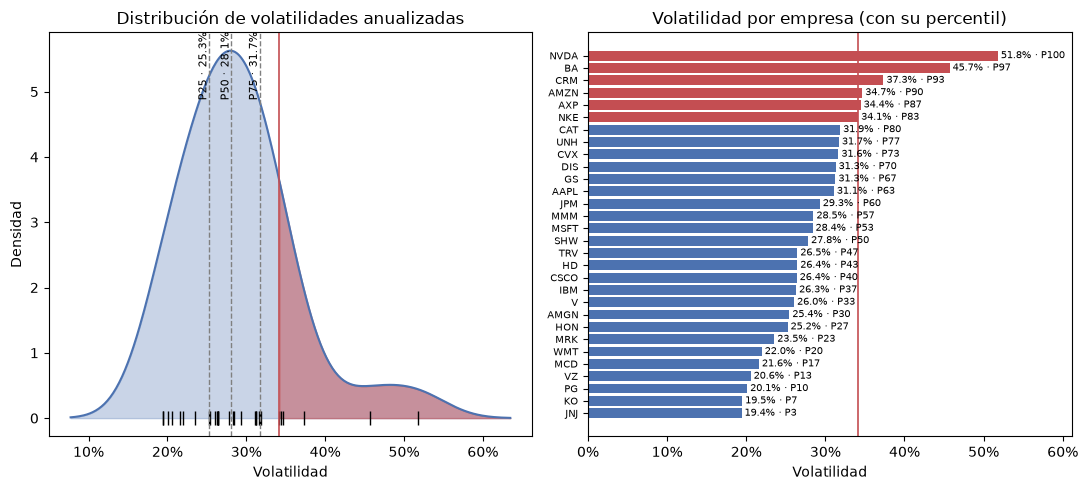

In [7]:
CORTE_PCT = 0.83   

tabla = vol.rename("volatilidad").to_frame().assign(volatil=pct >= CORTE_PCT)
volatiles = tabla.index[tabla["volatil"]].tolist()
no_volatiles = tabla.index[~tabla["volatil"]].tolist()
print(f"VOLÁTILES ({len(volatiles)}): {volatiles}")
print(f"NO VOLÁTILES ({len(no_volatiles)}): {no_volatiles}")

grafico(volatiles)  

## 3. Empresas volátiles y no volátiles

Estas son las empresas de cada grupo con su volatilidad anualizada.

In [8]:
for nombre, grupo in [("VOLÁTILES", volatiles), ("NO VOLÁTILES", no_volatiles)]:
    print(nombre)
    display(vol[grupo].sort_values(ascending=False).round(3).to_frame("volatilidad"))

VOLÁTILES


,volatilidad
symbol,
NVDA,0.518
BA,0.457
CRM,0.373
AMZN,0.347
AXP,0.344
NKE,0.341


NO VOLÁTILES


,volatilidad
symbol,
CAT,0.319
UNH,0.317
CVX,0.316
DIS,0.313
GS,0.313
AAPL,0.311
JPM,0.293
MMM,0.285
MSFT,0.284


## 4. Todos los tríos posibles: 2 no volátiles + 1 volátil

Evaluamos todos los tríos de 2 no volátiles + 1 volátil (276 parejas × 6 volátiles = 1.656). Filtros duros: las 3 empresas en sectores distintos y correlación media de 0,40 como máximo. La puntuación es la media de 5 percentiles: Sharpe, Sortino, drawdown, rentabilidad y baja correlación media.

### 4.1 Sector de cada empresa

In [9]:
yahoo = {t: yf.Ticker(t).info.get("sector") for t in sorted(precios.columns)}
filas = [f'"{t}": "{s}"' for t, s in yahoo.items()]
print("{\n" + ",\n".join("    " + ", ".join(filas[i:i + 4]) for i in range(0, len(filas), 4)) + ",\n}")

{
    "AAPL": "Technology", "AMGN": "Healthcare", "AMZN": "Consumer Cyclical", "AXP": "Financial Services",
    "BA": "Industrials", "CAT": "Industrials", "CRM": "Technology", "CSCO": "Technology",
    "CVX": "Energy", "DIS": "Communication Services", "GS": "Financial Services", "HD": "Consumer Cyclical",
    "HON": "Industrials", "IBM": "Technology", "JNJ": "Healthcare", "JPM": "Financial Services",
    "KO": "Consumer Defensive", "MCD": "Consumer Cyclical", "MMM": "Industrials", "MRK": "Healthcare",
    "MSFT": "Technology", "NKE": "Consumer Cyclical", "NVDA": "Technology", "PG": "Consumer Defensive",
    "SHW": "Basic Materials", "TRV": "Financial Services", "UNH": "Healthcare", "V": "Financial Services",
    "VZ": "Communication Services", "WMT": "Consumer Defensive",
}


In [10]:
sector = {
    "AAPL": "Technology", "AMGN": "Healthcare", "AMZN": "Consumer Cyclical", "AXP": "Financial Services",
    "BA": "Industrials", "CAT": "Industrials", "CRM": "Technology", "CSCO": "Technology",
    "CVX": "Energy", "DIS": "Communication Services", "GS": "Financial Services", "HD": "Consumer Cyclical",
    "HON": "Industrials", "IBM": "Technology", "JNJ": "Healthcare", "JPM": "Financial Services",
    "KO": "Consumer Defensive", "MCD": "Consumer Cyclical", "MMM": "Industrials", "MRK": "Healthcare",
    "MSFT": "Technology", "NKE": "Consumer Cyclical", "NVDA": "Technology", "PG": "Consumer Defensive",
    "SHW": "Basic Materials", "TRV": "Financial Services", "UNH": "Healthcare", "V": "Financial Services",
    "VZ": "Communication Services", "WMT": "Consumer Defensive",
}

### 4.2 Correlaciones entre las 30 empresas

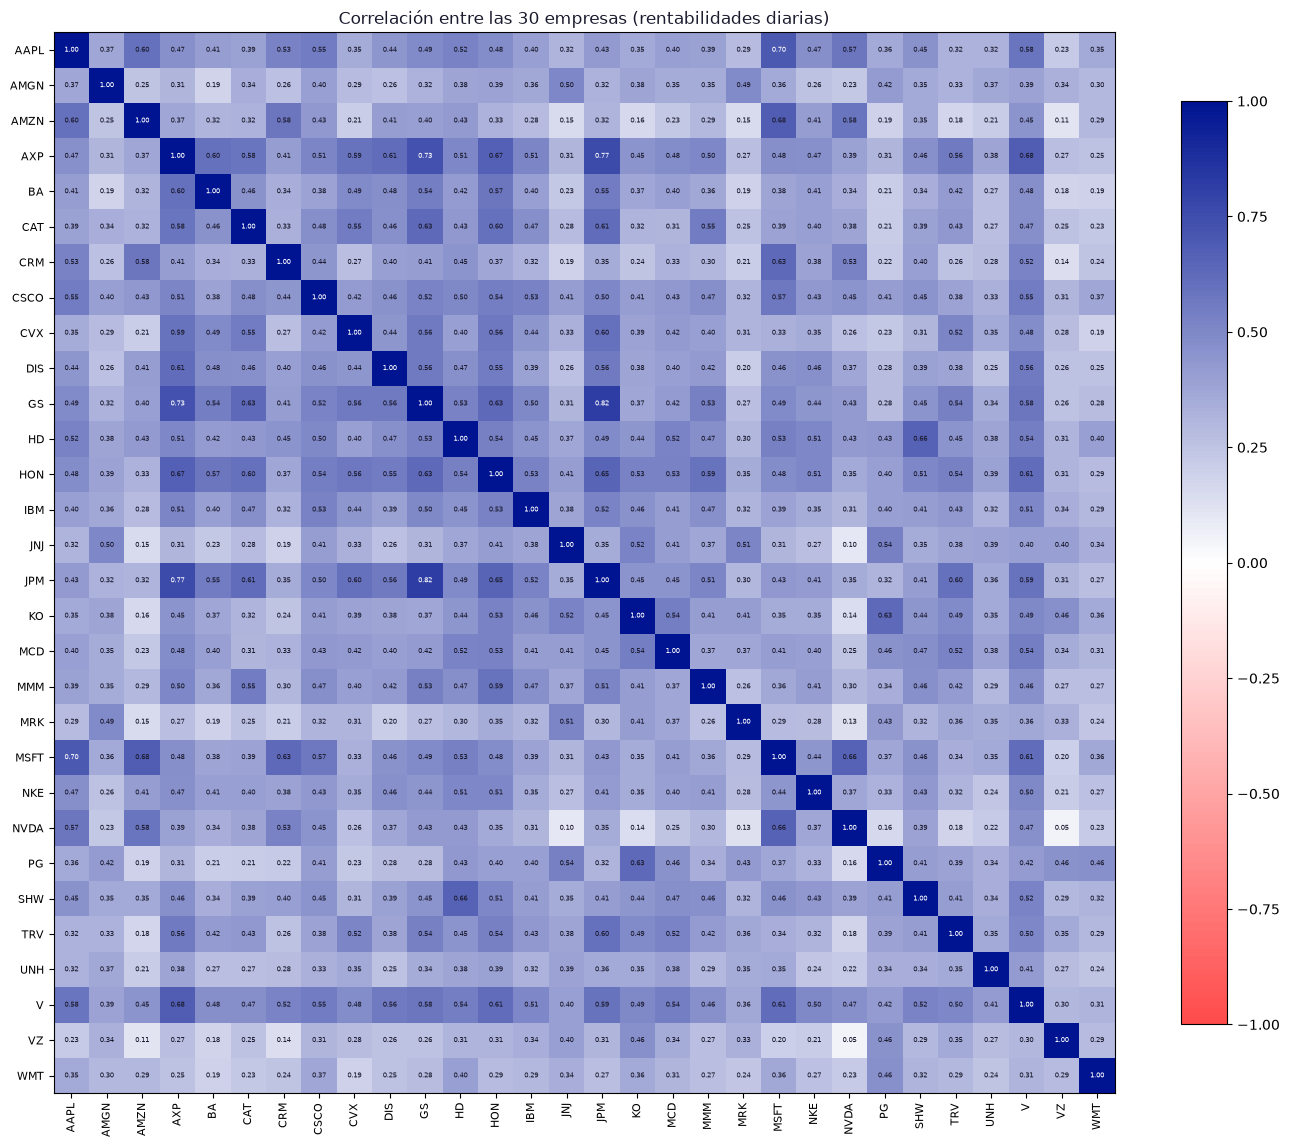

In [11]:
corr30 = rent.corr()
n = len(corr30)

fig, ax = plt.subplots(figsize=(14, 12))
im = ax.imshow(corr30, cmap=MAPA_CORR, vmin=-1, vmax=1)
ax.set_xticks(range(n), corr30.columns, rotation=90, fontsize=8)
ax.set_yticks(range(n), corr30.index, fontsize=8)
for i in range(n):
    for j in range(n):
        ax.text(j, i, f"{corr30.iloc[i, j]:.2f}", ha="center", va="center", fontsize=5,
                color="white" if corr30.iloc[i, j] > 0.7 else COLORES["gris_oscuro"])
fig.colorbar(im, shrink=0.8)
ax.set_title("Correlación entre las 30 empresas (rentabilidades diarias)", color=COLORES["gris_oscuro"])
plt.tight_layout()
plt.show()

### 4.3 Tríos y filtros duros

Cada trío es una cartera a pesos iguales (1/3 cada uno, rebalanceado a diario).

In [12]:
from itertools import combinations

rf = 0.01   # tasa libre de riesgo del enunciado (1 %)

def metricas(r):
    """Métricas anualizadas de una serie de rentabilidades diarias."""
    mu, sigma = r.mean() * DIAS_ANIO, r.std() * np.sqrt(DIAS_ANIO)
    caidas = np.minimum(r - rf / DIAS_ANIO, 0)
    acum = (1 + r).cumprod()
    return pd.Series({
        "rentabilidad": mu,
        "volatilidad": sigma,
        "sharpe": (mu - rf) / sigma,
        "sortino": (mu - rf) / np.sqrt((caidas**2).mean() * DIAS_ANIO),
        "drawdown": (acum / acum.cummax() - 1).min(),
    })

In [13]:
# Todos los tríos de 2 no volátiles + 1 volátil, con las 3 empresas en sectores distintos
todos = pd.DataFrame({
    " + ".join([*par, v]): metricas(rent[[*par, v]].mean(axis=1).dropna())
    for par in combinations(no_volatiles, 2)
    for v in volatiles
    if len({sector[e] for e in [*par, v]}) == 3
}).T

corr = [rent[t.split(" + ")].corr().values[np.triu_indices(3, 1)] for t in todos.index]
todos["corr_media"] = [c.mean() for c in corr]
todos["corr_max"] = [c.max() for c in corr]

# Filtro duro: correlación media máxima de 0,40 (el límite para las parejas, 0,70, lo decidimos después)
CORR_MEDIA_MAX = 0.40
print(f"{len(todos)} tríos con 3 sectores distintos")
todos = todos[todos["corr_media"] <= CORR_MEDIA_MAX]
print(f"{len(todos)} tríos con correlación media <= {CORR_MEDIA_MAX}")

1109 tríos con 3 sectores distintos
780 tríos con correlación media <= 0.4


### 4.4 Puntuación de cada trío

In [14]:
# Media de 5 percentiles entre los tríos que pasan los filtros (más es mejor; la correlación puntúa al revés)
pct = todos[["sharpe", "sortino", "drawdown", "rentabilidad"]].rank(pct=True)
pct["baja_corr"] = (-todos["corr_media"]).rank(pct=True)
todos["puntuacion"] = pct.mean(axis=1)

todos = todos.sort_values("puntuacion", ascending=False)
todos.head(10).round(3)

,rentabilidad,volatilidad,sharpe,sortino,drawdown,corr_media,corr_max,puntuacion
WMT + MRK + NVDA,0.312,0.231,1.307,1.969,-0.261,0.197,0.237,0.979
JNJ + WMT + NVDA,0.305,0.225,1.313,1.979,-0.291,0.221,0.338,0.953
PG + MRK + NVDA,0.282,0.228,1.192,1.785,-0.270,0.238,0.428,0.943
WMT + AMGN + NVDA,0.313,0.242,1.252,1.887,-0.286,0.250,0.295,0.942
WMT + TRV + NVDA,0.321,0.241,1.295,1.902,-0.303,0.232,0.292,0.940
WMT + UNH + NVDA,0.301,0.253,1.152,1.699,-0.286,0.231,0.245,0.932
JNJ + TRV + NVDA,0.286,0.232,1.191,1.739,-0.297,0.220,0.382,0.931
KO + MRK + NVDA,0.276,0.226,1.176,1.742,-0.289,0.226,0.407,0.929
MRK + TRV + NVDA,0.293,0.240,1.177,1.707,-0.297,0.224,0.364,0.928
WMT + CVX + NVDA,0.307,0.254,1.168,1.715,-0.302,0.228,0.264,0.924


### 4.5 Sharpe frente a correlación media

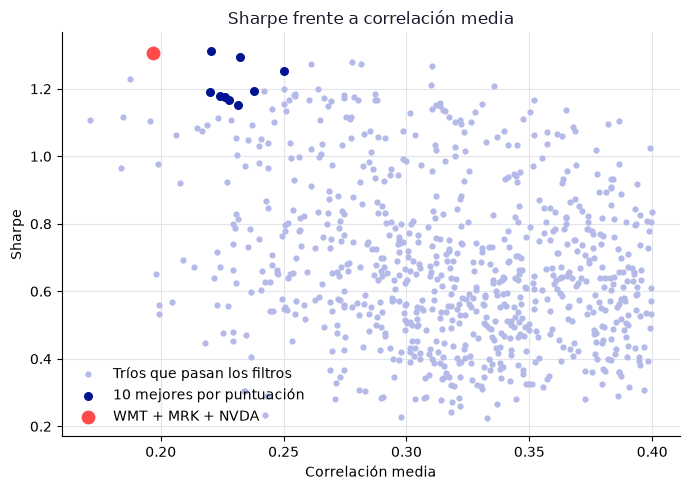

In [19]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(todos["corr_media"], todos["sharpe"], s=12, color=COLORES["azul_muy_claro"], label="Tríos que pasan los filtros")
ax.scatter(todos["corr_media"][:10], todos["sharpe"][:10], s=30, color=COLORES["azul_principal"], label="10 mejores por puntuación")
ax.scatter(todos["corr_media"].iloc[0], todos["sharpe"].iloc[0], s=80, color=COLORES["acento"], label=todos.index[0])
ax.set(xlabel="Correlación media", ylabel="Sharpe")
ax.set_title("Sharpe frente a correlación media", color=COLORES["gris_oscuro"])
ax.grid(color=COLORES["gris_claro"])
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

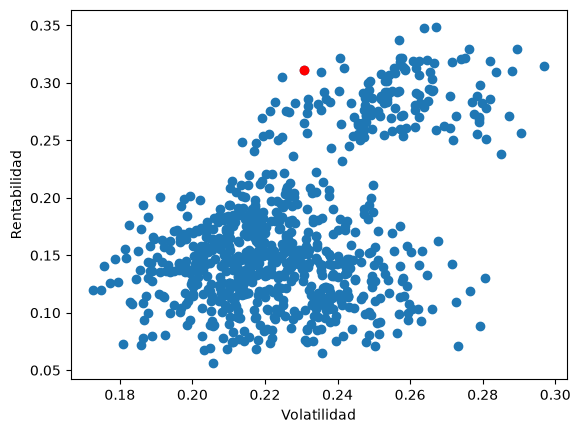

In [25]:
plt.scatter(todos["volatilidad"], todos["rentabilidad"])
plt.scatter(todos.loc["WMT + MRK + NVDA", "volatilidad"], todos.loc["WMT + MRK + NVDA", "rentabilidad"], color="red")
plt.xlabel("Volatilidad")
plt.ylabel("Rentabilidad")
plt.show()

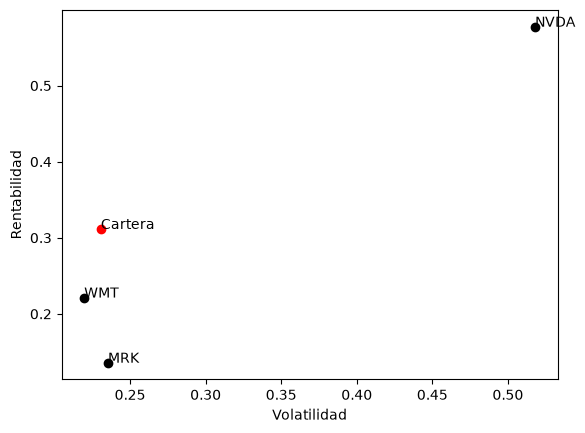

In [31]:
plt.scatter(todos.loc["WMT + MRK + NVDA", "volatilidad"], todos.loc["WMT + MRK + NVDA", "rentabilidad"], color="red")
plt.annotate("Cartera", (todos.loc["WMT + MRK + NVDA", "volatilidad"], todos.loc["WMT + MRK + NVDA", "rentabilidad"]))

for e in ["WMT", "MRK", "NVDA"]:
    vol_e, rent_e = rent[e].std() * np.sqrt(252), rent[e].mean() * 252
    plt.scatter(vol_e, rent_e, color="black")
    plt.annotate(e, (vol_e, rent_e))

plt.xlabel("Volatilidad"); plt.ylabel("Rentabilidad"); plt.show()

### 4.6 Correlaciones del mejor trío (nº 1 por puntuación)

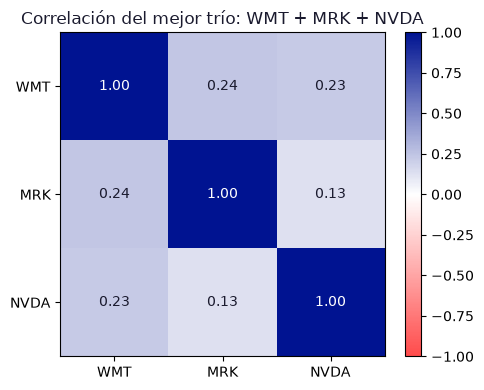

In [16]:
mejor = todos.index[0].split(" + ")
corr = rent[mejor].corr()

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(corr, cmap=MAPA_CORR, vmin=-1, vmax=1)
ax.set_xticks(range(3), mejor)
ax.set_yticks(range(3), mejor)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center",
                color="white" if corr.iloc[i, j] > 0.7 else COLORES["gris_oscuro"])
fig.colorbar(im)
ax.set_title(f"Correlación del mejor trío: {' + '.join(mejor)}", color=COLORES["gris_oscuro"])
plt.tight_layout()
plt.show()
